# Imports and Environment Setup

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

sys.path.insert(0,str(PROJECT_ROOT))

In [2]:
# PyTorch
import torch
import torch.nn.functional as F

# Data handling
import pandas as pd
import numpy as np

# Image processing
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Project modules
from src.config import (
    EMBEDDING_SIZE,
    NUM_CLASSES,
    BATCH_SIZE,
    CHECKPOINT_DIR,
)

from src.transforms import get_eval_transforms
from src.dataset import FaceRecognitionDataset
from src.face_recognition_model import FaceRecognitionModel

# Evaluation metrics
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
)


# Device and Project Path Configuration

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('Computation Device: ',device)

if torch.cuda.is_available():
    print('Device Name: ',torch.cuda.get_device_name(0))

# dataset,image and model checkpoints path 

IMAGE_DIR = (PROJECT_ROOT/'data'/'celeba'/'raw'/'img_align_celeba')

VALIDATION_CSV = (PROJECT_ROOT/'data'/'celeba'/'processed'/'validation.csv')

CHECKPOINT_PATH = (PROJECT_ROOT/'checkpoints'/'epoch_checkpoint.pth')

print("\nImage directory exists:", IMAGE_DIR.exists())
print("Validation CSV exists:", VALIDATION_CSV.exists())
print("Checkpoint exists:", CHECKPOINT_PATH.exists())

Computation Device:  cuda
Device Name:  NVIDIA GeForce GTX 1650

Image directory exists: True
Validation CSV exists: True
Checkpoint exists: True


# Load Validation Dataset

In [4]:
validation_df = pd.read_csv(VALIDATION_CSV)

validation_dataset = FaceRecognitionDataset(
    dataframe=validation_df,
    image_dir= IMAGE_DIR,
    transform= get_eval_transforms()
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
)

print("Validation images:", len(validation_dataset))
print("Validation identities:", validation_df["identity"].nunique())
print("Validation batches:", len(validation_loader))

Validation images: 16280
Validation identities: 629
Validation batches: 340


# Load Trained MobileFaceNet Model

In [5]:
# Initialize model
model = FaceRecognitionModel(
    embedding_size=EMBEDDING_SIZE,
    num_classes=NUM_CLASSES,
).to(device)

# Load checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

# Restore trained parameters
model.load_state_dict(
    checkpoint["model_state_dict"]
)

# Set evaluation mode
model.eval()

print("Completed epochs:", checkpoint["completed_epoch"])
print("Global training steps:", checkpoint["global_step"])
print("Model device:", device)

Completed epochs: 20
Global training steps: 54780
Model device: cuda


# Extract Validation Embeddings

In [6]:
# Store extracted embeddings and identity labels
all_embeddings = []
all_identities = []

model.eval()

with torch.no_grad():

    progress_bar = tqdm(
        validation_loader,
        desc="Extracting embeddings"
    )

    for images, identities in progress_bar:

        images = images.to(device, non_blocking=True)

        # Extract facial embeddings
        embeddings = model.backbone(images)

        # Normalize embeddings for cosine similarity
        embeddings = F.normalize(embeddings, p=2, dim=1)

        all_embeddings.append(embeddings.cpu())
        all_identities.extend(identities.tolist())


# Combine all batches
all_embeddings = torch.cat(all_embeddings, dim=0)

all_identities = np.array(all_identities)


print("Embeddings shape:", all_embeddings.shape)
print("Identity labels shape:", all_identities.shape)

Extracting embeddings:   0%|          | 0/340 [00:00<?, ?it/s]

Embeddings shape: torch.Size([16280, 128])
Identity labels shape: (16280,)


# Generate Genuine and Impostor Pairs

In [7]:
# Group image indices by identity
identity_to_indices = {}

for index, identity in enumerate(all_identities):

    identity_to_indices.setdefault(
        identity, []
    ).append(index)


# Random generator for reproducibility
rng = np.random.default_rng(42)

genuine_pairs = []
impostor_pairs = []

identities = list(identity_to_indices.keys())

# Generate genuine pairs
while len(genuine_pairs) < 25000:

    identity = rng.choice(identities)

    indices = identity_to_indices[identity]

    if len(indices) < 2:
        continue

    pair = rng.choice(indices, size=2, replace=False)

    genuine_pairs.append(pair)


# Generate impostor pairs
while len(impostor_pairs) < 25000:

    selected_identities = rng.choice(
        identities,
        size=2,
        replace=False
    )

    index_1 = rng.choice(
        identity_to_indices[selected_identities[0]]
    )

    index_2 = rng.choice(
        identity_to_indices[selected_identities[1]]
    )

    impostor_pairs.append([index_1, index_2])


# Convert to NumPy arrays
genuine_pairs = np.array(genuine_pairs)
impostor_pairs = np.array(impostor_pairs)

print("Genuine pairs:", len(genuine_pairs))
print("Impostor pairs:", len(impostor_pairs))
print("Total pairs:", len(genuine_pairs) + len(impostor_pairs))

Genuine pairs: 25000
Impostor pairs: 25000
Total pairs: 50000


# Calculate Cosine Similarity

In [8]:
# Calculate genuine pair similarities
genuine_indices_1 = torch.tensor(genuine_pairs[:, 0])
genuine_indices_2 = torch.tensor(genuine_pairs[:, 1])

genuine_scores = torch.sum(
    all_embeddings[genuine_indices_1] *
    all_embeddings[genuine_indices_2],
    dim=1
)


# Calculate impostor pair similarities
impostor_indices_1 = torch.tensor(impostor_pairs[:, 0])
impostor_indices_2 = torch.tensor(impostor_pairs[:, 1])

impostor_scores = torch.sum(
    all_embeddings[impostor_indices_1] *
    all_embeddings[impostor_indices_2],
    dim=1
)


# Combine scores and labels
similarity_scores = torch.cat(
    [genuine_scores, impostor_scores]
).numpy()

pair_labels = np.concatenate([
    np.ones(len(genuine_scores)),
    np.zeros(len(impostor_scores))
])



print("Genuine score shape:", genuine_scores.shape)
print("Impostor score shape:", impostor_scores.shape)
print("Combined score shape:", similarity_scores.shape)

Genuine score shape: torch.Size([25000])
Impostor score shape: torch.Size([25000])
Combined score shape: (50000,)


In [9]:
print("Genuine similarity:")
print("Mean:", genuine_scores.mean().item())
print("Minimum:", genuine_scores.min().item())
print("Maximum:", genuine_scores.max().item())

print("\nImpostor similarity:")
print("Mean:", impostor_scores.mean().item())
print("Minimum:", impostor_scores.min().item())
print("Maximum:", impostor_scores.max().item())

Genuine similarity:
Mean: 0.9732996821403503
Minimum: 0.9038472175598145
Maximum: 0.9998971223831177

Impostor similarity:
Mean: 0.9298596382141113
Minimum: 0.8819900155067444
Maximum: 0.9891998171806335


# ROC-AUC

In [10]:
roc_auc = roc_auc_score(
    pair_labels,
    similarity_scores
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9699409400000001


# Plot similarity distributions

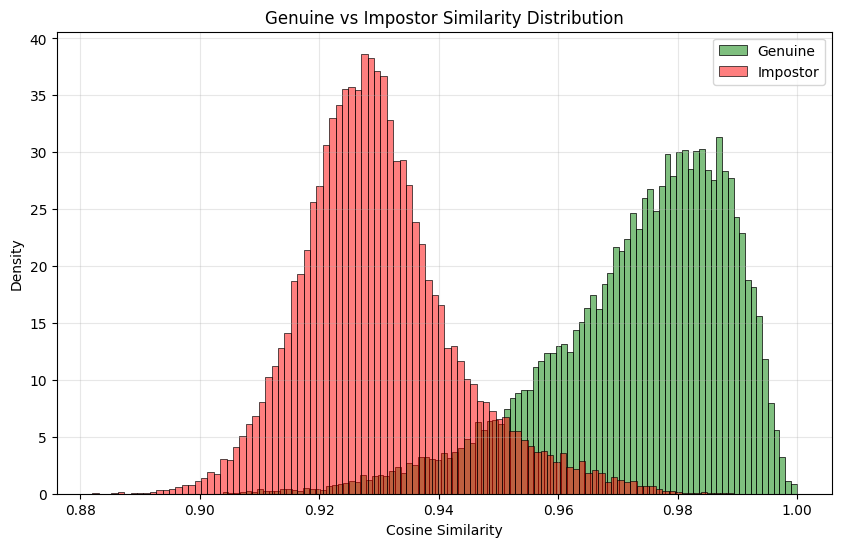

In [11]:
plt.figure(figsize=(10, 6))

sns.histplot(
    genuine_scores.numpy(),
    bins=100,
    color="green",
    label="Genuine",
    stat="density",
    alpha=0.5
)

sns.histplot(
    impostor_scores.numpy(),
    bins=100,
    color="red",
    label="Impostor",
    stat="density",
    alpha=0.5
)

plt.title("Genuine vs Impostor Similarity Distribution")
plt.xlabel("Cosine Similarity")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Calculate Equal Error Rate (EER)

In [12]:
# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    pair_labels,
    similarity_scores
)

# Calculate False Rejection Rate
fnr = 1 - tpr

# Find the point where FAR and FRR are closest
eer_index = np.nanargmin(np.abs(fpr - fnr))

eer = (fpr[eer_index] + fnr[eer_index]) / 2
eer_threshold = thresholds[eer_index]

print("Equal Error Rate:", eer)
print("EER Percentage:", eer * 100, "%")
print("Threshold at EER:", eer_threshold)
print("FAR at EER:", fpr[eer_index])
print("FRR at EER:", fnr[eer_index])

Equal Error Rate: 0.08113999999999999
EER Percentage: 8.113999999999999 %
Threshold at EER: 0.9491418
FAR at EER: 0.08116
FRR at EER: 0.08111999999999997


# Evaluate different thresholds

In [13]:
threshold_values = [
    0.93,
    0.94,
    0.945,
    0.94914,
    0.95,
    0.96,
    0.97,
    0.98
]

threshold_results = []

for threshold in threshold_values:

    predictions = (similarity_scores >= threshold).astype(int)

    genuine_mask = pair_labels == 1
    impostor_mask = pair_labels == 0

    far = np.mean(predictions[impostor_mask] == 1)
    frr = np.mean(predictions[genuine_mask] == 0)

    tar = 1 - frr

    threshold_results.append({
        "Threshold": threshold,
        "FAR": far,
        "FRR": frr,
        "TAR": tar
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,FAR,FRR,TAR
0,0.93000,0.44580,0.01448,0.98552
1,0.94000,0.18064,0.03884,0.96116
2,0.94500,0.11608,0.05780,0.94220
3,0.94914,0.08120,0.08112,0.91888
4,0.95000,0.07504,0.08692,0.91308
5,0.96000,0.02876,0.18500,0.81500
6,0.97000,0.00752,0.34700,0.65300
7,0.98000,0.00076,0.60172,0.39828


# Plot the ROC curve

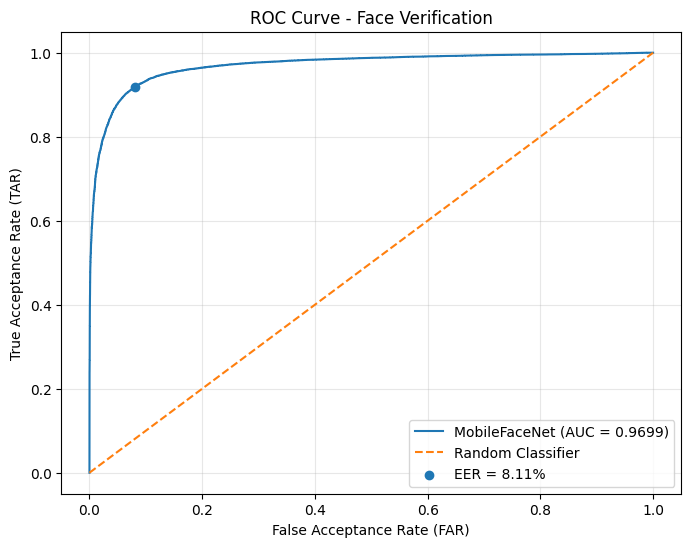

In [14]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"MobileFaceNet (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.scatter(
    fpr[eer_index],
    tpr[eer_index],
    label=f"EER = {eer * 100:.2f}%"
)

plt.xlabel("False Acceptance Rate (FAR)")
plt.ylabel("True Acceptance Rate (TAR)")
plt.title("ROC Curve - Face Verification")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Save validation results

In [15]:
validation_results = {
    "roc_auc": roc_auc,
    "eer": eer,
    "eer_threshold": eer_threshold,
    "far_at_eer": fpr[eer_index],
    "frr_at_eer": fnr[eer_index],
    "validation_images": len(validation_dataset),
    "genuine_pairs": len(genuine_pairs),
    "impostor_pairs": len(impostor_pairs)
}

validation_results_df = pd.DataFrame(
    [validation_results]
)

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

validation_results_df.to_csv(
    RESULTS_DIR / "validation_metrics.csv",
    index=False
)


display(validation_results_df)

,roc_auc,eer,eer_threshold,far_at_eer,frr_at_eer,validation_images,genuine_pairs,impostor_pairs
0,0.969941,0.08114,0.949142,0.08116,0.08112,16280,25000,25000


# Final Test Evaluation

In [16]:
TEST_CSV = (
    PROJECT_ROOT / "data" / "celeba" / "processed" / "test.csv"
)

test_df = pd.read_csv(TEST_CSV)

test_dataset = FaceRecognitionDataset(
    dataframe=test_df,
    image_dir=IMAGE_DIR,
    transform=get_eval_transforms(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
)

print("Test images:", len(test_dataset))
print("Test identities:", test_df["identity"].nunique())
print("Test batches:", len(test_loader))

sample_image, sample_identity = test_dataset[0]

print("Image shape:", sample_image.shape)
print("Identity:", sample_identity)

Test images: 16027
Test identities: 616
Test batches: 334
Image shape: torch.Size([3, 112, 112])
Identity: 4930


# Extract test embeddings

In [17]:
all_test_embeddings = []
all_test_identities = []

model.eval()

with torch.no_grad():

    progress_bar = tqdm(
        test_loader,
        desc="Extracting test embeddings"
    )

    for images, identities in progress_bar:

        images = images.to(
            device,
            non_blocking=True
        )

        embeddings = model.backbone(images)

        embeddings = F.normalize(
            embeddings,
            p=2,
            dim=1
        )

        all_test_embeddings.append(
            embeddings.cpu()
        )

        all_test_identities.extend(
            identities.tolist()
        )

all_test_embeddings = torch.cat(
    all_test_embeddings,
    dim=0
)

all_test_identities = np.array(
    all_test_identities
)

print("Embeddings shape:", all_test_embeddings.shape)
print("Identity labels shape:", all_test_identities.shape)

Extracting test embeddings:   0%|          | 0/334 [00:00<?, ?it/s]

Embeddings shape: torch.Size([16027, 128])
Identity labels shape: (16027,)


# Generate test pairs

In [18]:
test_identity_to_indices = {}

for index, identity in enumerate(all_test_identities):
    test_identity_to_indices.setdefault(identity, []).append(index)

rng = np.random.default_rng(42)

test_genuine_pairs = []
test_impostor_pairs = []

test_identities = list(test_identity_to_indices.keys())

# Generate genuine pairs
while len(test_genuine_pairs) < 25000:

    identity = rng.choice(test_identities)
    indices = test_identity_to_indices[identity]

    if len(indices) < 2:
        continue

    pair = rng.choice(
        indices,
        size=2,
        replace=False
    )

    test_genuine_pairs.append(pair)

# Generate impostor pairs
while len(test_impostor_pairs) < 25000:

    selected_identities = rng.choice(
        test_identities,
        size=2,
        replace=False
    )

    index_1 = rng.choice(
        test_identity_to_indices[selected_identities[0]]
    )

    index_2 = rng.choice(
        test_identity_to_indices[selected_identities[1]]
    )

    test_impostor_pairs.append([index_1, index_2])

test_genuine_pairs = np.array(test_genuine_pairs)
test_impostor_pairs = np.array(test_impostor_pairs)

print("Test genuine pairs:", len(test_genuine_pairs))
print("Test impostor pairs:", len(test_impostor_pairs))
print(
    "Total test pairs:",
    len(test_genuine_pairs) + len(test_impostor_pairs)
)

Test genuine pairs: 25000
Test impostor pairs: 25000
Total test pairs: 50000


# Calculate test similarity scores

In [19]:
# Genuine pair similarities
test_genuine_indices_1 = torch.tensor(
    test_genuine_pairs[:, 0]
)

test_genuine_indices_2 = torch.tensor(
    test_genuine_pairs[:, 1]
)

test_genuine_scores = torch.sum(
    all_test_embeddings[test_genuine_indices_1] *
    all_test_embeddings[test_genuine_indices_2],
    dim=1
)

# Impostor pair similarities
test_impostor_indices_1 = torch.tensor(
    test_impostor_pairs[:, 0]
)

test_impostor_indices_2 = torch.tensor(
    test_impostor_pairs[:, 1]
)

test_impostor_scores = torch.sum(
    all_test_embeddings[test_impostor_indices_1] *
    all_test_embeddings[test_impostor_indices_2],
    dim=1
)

# Combine scores and labels
test_similarity_scores = torch.cat([
    test_genuine_scores,
    test_impostor_scores
]).numpy()

test_pair_labels = np.concatenate([
    np.ones(len(test_genuine_scores)),
    np.zeros(len(test_impostor_scores))
])


print("Genuine scores:", test_genuine_scores.shape)
print("Impostor scores:", test_impostor_scores.shape)
print("Combined scores:", test_similarity_scores.shape)

Genuine scores: torch.Size([25000])
Impostor scores: torch.Size([25000])
Combined scores: (50000,)


# Inspect test similarity scores

In [20]:
print("Genuine similarity:")
print("Mean:", test_genuine_scores.mean().item())
print("Minimum:", test_genuine_scores.min().item())
print("Maximum:", test_genuine_scores.max().item())

print("\nImpostor similarity:")
print("Mean:", test_impostor_scores.mean().item())
print("Minimum:", test_impostor_scores.min().item())
print("Maximum:", test_impostor_scores.max().item())

Genuine similarity:
Mean: 0.9746016263961792
Minimum: 0.9013290405273438
Maximum: 0.9999998807907104

Impostor similarity:
Mean: 0.9298670291900635
Minimum: 0.8875691294670105
Maximum: 0.9935001134872437


# Calculate Test ROC-AUC

In [21]:
test_roc_auc = roc_auc_score(
    test_pair_labels,
    test_similarity_scores
)

print("Test ROC-AUC:", test_roc_auc)

Test ROC-AUC: 0.9747008712


# Calculate Test EER

In [22]:
test_fpr, test_tpr, test_thresholds = roc_curve(
    test_pair_labels,
    test_similarity_scores
)

test_fnr = 1 - test_tpr

test_eer_index = np.nanargmin(
    np.abs(test_fpr - test_fnr)
)

test_eer = (
    test_fpr[test_eer_index] +
    test_fnr[test_eer_index]
) / 2

print("Test EER:", test_eer)
print("Test EER Percentage:", test_eer * 100, "%")
print("Test FAR:", test_fpr[test_eer_index])
print("Test FRR:", test_fnr[test_eer_index])
print("Test EER threshold:", test_thresholds[test_eer_index])

Test EER: 0.07353999999999998
Test EER Percentage: 7.353999999999998 %
Test FAR: 0.07352
Test FRR: 0.07355999999999996
Test EER threshold: 0.9495422


# Evaluate test performance at the frozen threshold

In [23]:
# Use the frozen validation threshold
FINAL_THRESHOLD = eer_threshold

# Generate test predictions
test_predictions = (
    test_similarity_scores >= FINAL_THRESHOLD
).astype(int)

# Separate genuine and impostor pairs
genuine_mask = test_pair_labels == 1
impostor_mask = test_pair_labels == 0

# Calculate FAR, FRR and TAR
test_far = np.mean(
    test_predictions[impostor_mask] == 1
)

test_frr = np.mean(
    test_predictions[genuine_mask] == 0
)

test_tar = 1 - test_frr

# Overall pair classification accuracy
test_accuracy = np.mean(
    test_predictions == test_pair_labels
)

print("FINAL TEST EVALUATION")
print("---------------------")
print("Frozen Threshold:", FINAL_THRESHOLD)
print("Test Accuracy:", test_accuracy * 100, "%")
print("Test FAR:", test_far * 100, "%")
print("Test FRR:", test_frr * 100, "%")
print("Test TAR:", test_tar * 100, "%")

FINAL TEST EVALUATION
---------------------
Frozen Threshold: 0.9491418
Test Accuracy: 92.646 %
Test FAR: 7.611999999999999 %
Test FRR: 7.095999999999999 %
Test TAR: 92.904 %


In [25]:
test_results = {
    "roc_auc": test_roc_auc,
    "eer": test_eer,
    "eer_threshold": test_thresholds[test_eer_index],
    "frozen_validation_threshold": FINAL_THRESHOLD,
    "test_accuracy": test_accuracy,
    "test_far": test_far,
    "test_frr": test_frr,
    "test_tar": test_tar,
    "test_images": len(test_dataset),
    "test_identities": test_df["identity"].nunique(),
    "genuine_pairs": len(test_genuine_pairs),
    "impostor_pairs": len(test_impostor_pairs)
}

test_results_df = pd.DataFrame([test_results])

test_results_df.to_csv(
    RESULTS_DIR / "test_metrics.csv",
    index=False
)


display(test_results_df.T)

,0
roc_auc,0.974701
eer,0.073540
eer_threshold,0.949542
frozen_validation_threshold,0.949142
test_accuracy,0.926460
test_far,0.076120
test_frr,0.070960
test_tar,0.929040
test_images,16027.000000
test_identities,616.000000
